# Практическое занятие №2: Градиентный спуск и оптимизаторы
**Цели занятия:**
- Научиться визуализировать функции потерь двух переменных (3D и линии уровня).
- Реализовать простой градиентный спуск (SGD) с помощью PyTorch и проследить траекторию оптимизации.
- Познакомиться с основными оптимизаторами из семейства gradient descent: SGD с моментом, RMSprop, Adam.
- Исследовать влияние скорости обучения (learning rate) на сходимость.

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Все ячейки тетрадки преподавателя выполнены, задания 1–6 и вопросы к ним — ниже по тексту (ответы и выводы
> сразу после соответствующих графиков). Нейросети здесь не обучаются — оптимизируются функции двух переменных,
> поэтому вычисления выполняются на CPU; первая ячейка кода — общие настройки запуска, одинаковые для всех практик.
>
> Дополнения: интерактивные 3D-графики plotly продублированы статичными копиями в matplotlib (plotly-график виден
> только в запущенном Jupyter); анимация сохраняется видеороликом (нужен `ffmpeg`), а без него — JS-анимацией.
>
> **Исправления ошибок заготовки.** В ячейке задания 4 использовался список минимумов `minima`, который нигде не
> был задан, — он определён в ячейке с функциями. В ячейке с анимацией используются траектории SGD и Adam, а
> предыдущая ячейка перезаписывала словарь `trajectories` (оставался только SGD+Momentum), из-за чего анимация
> падала с `KeyError`; результаты задания 5 теперь хранятся в отдельной переменной.

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


Слова "**Задание**" выделены жирным шрифтом по тексту.

## 1. Импорт необходимых библиотек
Установка и импорт:
- `torch` для автоматического дифференцирования и оптимизаторов.
- `numpy` для численных операций.
- `matplotlib` для построения графиков (3D, контурные, анимация).
- `ipywidgets` (опционально) для интерактивности.

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import animation
from matplotlib.colors import LogNorm
from IPython.display import HTML
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
import time
import warnings
warnings.filterwarnings('ignore')

# plotly: интерактивный вывод для Jupyter/VS Code (mimetype) и для классического Notebook (html)
pio.renderers.default = "plotly_mimetype+notebook_connected"

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 2. Функции для визуализации
Определим две классические тестовые функции:
- **Функция Розенброка** (Rosenbrock) — «овражная» функция, сложная для оптимизации:
  $$f(x,y) = (a - x)^2 + b\,(y - x^2)^2,\quad a=1,\; b=100.$$
  Глобальный минимум в точке $(1,1)$.
- **Функция Химмельблау** (Himmelblau) — с несколькими локальными минимумами:
  $$f(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2.$$
  Четыре локальных минимума: $(3,2)$, $(-2.805,3.131)$, $(-3.779,-3.283)$, $(3.584,-1.848)$.

In [3]:
def rosenbrock(x, y, a=1, b=100):
    return (a - x)**2 + b * (y - x**2)**2

def himmelblau(x, y):
    return (x**2 + y - 11)**2 + (x + y**2 - 7)**2

# Создадим сетку для построения графиков
x = np.linspace(-2, 2, 100)
y = np.linspace(-1, 3, 100)
X, Y = np.meshgrid(x, y)
Z_rosen = rosenbrock(X, Y)

# Для Химмельблау возьмём более широкий диапазон
x_h = np.linspace(-5, 5, 100)
y_h = np.linspace(-5, 5, 100)
X_h, Y_h = np.meshgrid(x_h, y_h)
Z_himm = himmelblau(X_h, Y_h)

# Точки минимумов (используются на всех графиках ниже)
rosen_min = (1.0, 1.0)
minima = [(3.0, 2.0), (-2.805118, 3.131312), (-3.779310, -3.283186), (3.584428, -1.848126)]
print("f_Rosenbrock(1, 1) =", rosenbrock(*rosen_min))
print("f_Himmelblau в минимумах:", [round(himmelblau(mx, my), 10) for mx, my in minima])

f_Rosenbrock(1, 1) = 0.0
f_Himmelblau в минимумах: [0.0, 0.0, 0.0, 0.0]


### 2.1 3D-визуализация функций
**Задание 1**: построить поверхности функций Розенброка и Химмельблау в 3D с возможностью интерактивного вращения. Обратите внимание на овраг у Розенброка и несколько впадин у Химмельблау.

Пример можно взять из лекции (библиотека plotly).

In [4]:
# Задание 1. Интерактивные 3D-поверхности (plotly): график можно вращать и приближать мышью
fig = make_subplots(rows=1, cols=2, specs=[[{"type": "surface"}, {"type": "surface"}]],
                    subplot_titles=("Функция Розенброка", "Функция Химмельблау"))
# Для Розенброка цвет — по log10(1 + f): иначе весь «овраг» сливается в один цвет
s_ = slice(None, None, 2)    # для интерактивного графика хватит сетки 50x50 (меньше размер файла)
fig.add_trace(go.Surface(x=X[s_, s_], y=Y[s_, s_], z=Z_rosen[s_, s_], surfacecolor=np.log10(1 + Z_rosen[s_, s_]), colorscale="Viridis",
                         showscale=False, name="Rosenbrock"), row=1, col=1)
fig.add_trace(go.Scatter3d(x=[1], y=[1], z=[0], mode="markers", marker=dict(size=6, color="red"),
                           name="минимум (1, 1)"), row=1, col=1)
fig.add_trace(go.Surface(x=X_h[s_, s_], y=Y_h[s_, s_], z=Z_himm[s_, s_], surfacecolor=np.log10(1 + Z_himm[s_, s_]), colorscale="Plasma",
                         showscale=False, name="Himmelblau"), row=1, col=2)
fig.add_trace(go.Scatter3d(x=[m[0] for m in minima], y=[m[1] for m in minima], z=[0] * 4, mode="markers",
                           marker=dict(size=6, color="cyan"), name="4 минимума"), row=1, col=2)
fig.update_layout(height=550, width=1100, margin=dict(l=0, r=0, t=40, b=0))
fig.show()

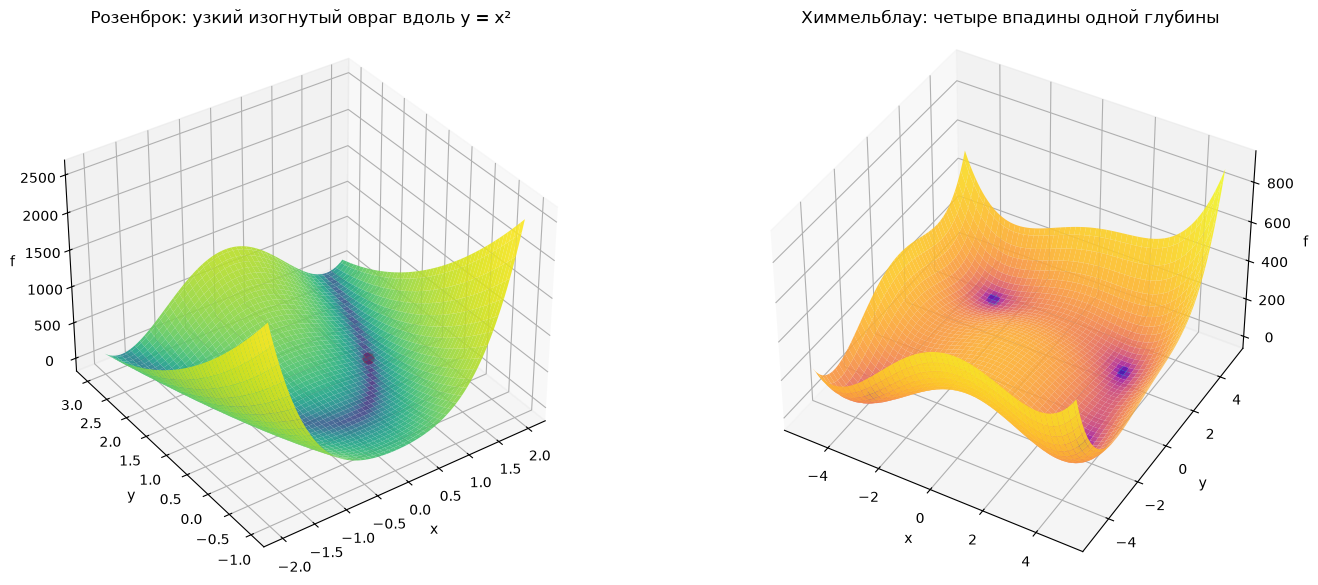

In [5]:
# Статичная копия тех же поверхностей (matplotlib) — видна и без запущенного Jupyter
fig = plt.figure(figsize=(15, 6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(X, Y, Z_rosen, cmap="viridis", norm=LogNorm(vmin=0.1, vmax=Z_rosen.max()),
                linewidth=0, antialiased=True, alpha=0.9)
ax.scatter([1], [1], [0], color="red", s=60, depthshade=False)
ax.set_title("Розенброк: узкий изогнутый овраг вдоль y = x²")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f")
ax.view_init(elev=35, azim=-125)

ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.plot_surface(X_h, Y_h, Z_himm, cmap="plasma", norm=LogNorm(vmin=0.1, vmax=Z_himm.max()),
                linewidth=0, antialiased=True, alpha=0.9)
ax.scatter([m[0] for m in minima], [m[1] for m in minima], [0] * 4, color="cyan", s=60, depthshade=False)
ax.set_title("Химмельблау: четыре впадины одной глубины")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f")
ax.view_init(elev=40, azim=-60)
plt.tight_layout()
plt.show()

### 2.2 Контурные графики (линии уровня)
**Задание 2.** Нарисовать контурные графиках и точки глобальных (или локальных) минимумов на них.
Можно matplotlib или seaborn. (Проявить фантазию в оформлении!)

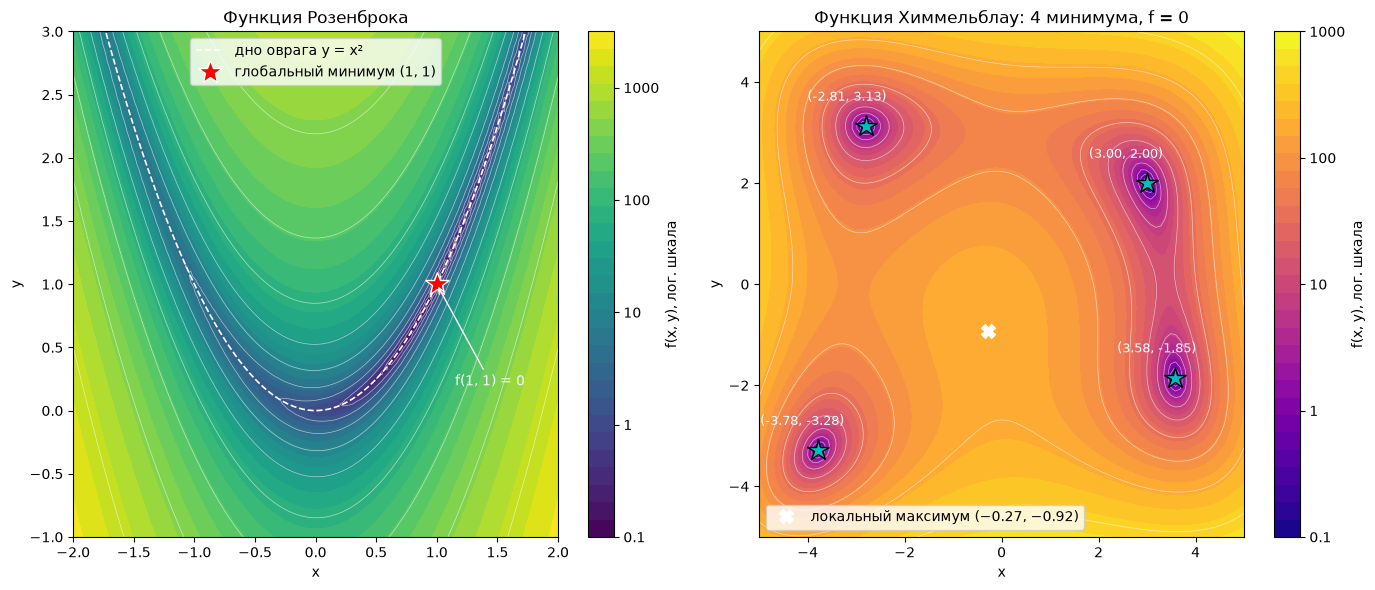

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Розенброк: заливка по логарифмической шкале + линии уровня + «дно оврага» y = x^2
ax = axes[0]
cf = ax.contourf(X, Y, Z_rosen, levels=np.logspace(-1, 3.5, 30), norm=LogNorm(), cmap="viridis")
ax.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3.5, 12), colors="white", linewidths=0.5, alpha=0.6)
ax.plot(x, x**2, "w--", lw=1.2, label="дно оврага y = x²")
ax.plot(*rosen_min, "r*", ms=18, mec="white", label="глобальный минимум (1, 1)")
ax.annotate("f(1, 1) = 0", rosen_min, xytext=(1.15, 0.2), color="white",
            arrowprops=dict(arrowstyle="->", color="white"))
ax.set_xlim(-2, 2); ax.set_ylim(-1, 3)
cb = fig.colorbar(cf, ax=ax, label="f(x, y), лог. шкала")
cb.set_ticks([0.1, 1, 10, 100, 1000]); cb.set_ticklabels(["0.1", "1", "10", "100", "1000"])
ax.set_title("Функция Розенброка"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper center")

# Химмельблау: четыре равноценных минимума и седловые области между ними
ax = axes[1]
cf = ax.contourf(X_h, Y_h, Z_himm, levels=np.logspace(-1, 3.0, 30), norm=LogNorm(), cmap="plasma")
ax.contour(X_h, Y_h, Z_himm, levels=np.logspace(-1, 3.0, 12), colors="white", linewidths=0.5, alpha=0.6)
for k, (mx, my) in enumerate(minima):
    ax.plot(mx, my, "c*", ms=16, mec="k")
    ax.annotate(f"({mx:.2f}, {my:.2f})", (mx, my), xytext=(mx - 1.2, my + 0.5), color="white", fontsize=9)
ax.plot(-0.270845, -0.923039, "wX", ms=10, label="локальный максимум (−0.27, −0.92)")
cb = fig.colorbar(cf, ax=ax, label="f(x, y), лог. шкала")
cb.set_ticks([0.1, 1, 10, 100, 1000]); cb.set_ticklabels(["0.1", "1", "10", "100", "1000"])
ax.set_title("Функция Химмельблау: 4 минимума, f = 0"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

**Задание 3.** Изучите полученные графики. Почему функция Розенброка считается сложной для градиентного спуска? (Ответьте в ячейке ниже)

In [7]:
# Количественная проверка «сложности»: собственные числа гессиана в минимумах
from torch.autograd.functional import hessian

def hess_eig(func, point):
    H = hessian(lambda p: func(p[0], p[1]), torch.tensor(point, dtype=torch.float64))
    return torch.linalg.eigvalsh(H).numpy()

ev = hess_eig(rosenbrock, rosen_min)
print(f"Розенброк, минимум (1, 1): собственные числа гессиана {ev.round(3)}, число обусловленности {ev.max() / ev.min():.0f}")
for m in minima:
    ev = hess_eig(himmelblau, m)
    print(f"Химмельблау, минимум ({m[0]:.2f}, {m[1]:.2f}): собственные числа {ev.round(2)}, обусловленность {ev.max() / ev.min():.1f}")

# Длина градиента вдоль дна оврага и поперёк него
for px in [-1.5, -1.0, 0.0, 0.5]:
    p = torch.tensor([px, px**2], requires_grad=True)
    rosenbrock(p[0], p[1]).backward()
    print(f"точка на дне оврага ({px:+.1f}, {px**2:.2f}): |grad| = {p.grad.norm():.2f}")
p = torch.tensor([-1.5, 1.5], requires_grad=True)
rosenbrock(p[0], p[1]).backward()
print(f"стартовая точка (-1.5, 1.5) над оврагом: |grad| = {p.grad.norm():.1f}")

Розенброк, минимум (1, 1): собственные числа гессиана [3.990000e-01 1.001601e+03], число обусловленности 2508
Химмельблау, минимум (3.00, 2.00): собственные числа [25.72 82.28], обусловленность 3.2
Химмельблау, минимум (-2.81, 3.13): собственные числа [64.84 80.55], обусловленность 1.2
Химмельблау, минимум (-3.78, -3.28): собственные числа [ 70.71 133.79], обусловленность 1.9
Химмельблау, минимум (3.58, -1.85): собственные числа [ 28.69 105.42], обусловленность 3.7
точка на дне оврага (-1.5, 2.25): |grad| = 5.00
точка на дне оврага (-1.0, 1.00): |grad| = 4.00
точка на дне оврага (+0.0, 0.00): |grad| = 2.00
точка на дне оврага (+0.5, 0.25): |grad| = 1.00
стартовая точка (-1.5, 1.5) над оврагом: |grad| = 479.1


Минимум функции Розенброка лежит на дне узкого изогнутого оврага вдоль параболы $y = x^2$. На 3D-графиках и линиях уровня это вытянутая серповидная впадина. Отсюда три трудности.

1. **Крутизна по разным направлениям сильно различается.** В минимуме (1, 1) собственные числа гессиана 0,399 и 1001,6, число обусловленности ≈ 2508: поперёк оврага функция в 2500 раз круче, чем вдоль него. Для сравнения, у Химмельблау обусловленность в минимумах от 1,2 до 3,7, впадины почти круглые.
2. **Градиент направлен не туда, куда нужно идти.** В стартовой точке (−1,5; 1,5) над оврагом длина градиента 479, а на дне оврага — от 1 до 5 (в точке (0,5; 0,25) — 1,0). Антиградиент смотрит почти поперёк оврага, к его дну, а не вдоль дна к минимуму.
3. **Шаг приходится выбирать по худшему направлению.** При большом lr точка перепрыгивает через овраг, раскачивается или расходится. При малом lr точка после спуска на дно движется вдоль него крошечными шагами, ведь градиент там мал. К тому же дно изогнуто, и направление движения всё время меняется.

Итог: градиентный спуск быстро находит дно оврага, но очень долго идёт по нему к (1, 1). Это и проверяется в заданиях 4–6.

## 3. Реализация градиентного спуска (SGD) с помощью PyTorch

Будем минимизировать функцию двух переменных, используя автоматическое дифференцирование PyTorch. Создадим тензоры с включённым `requires_grad=True` и на каждом шаге будем обновлять их с помощью правила SGD:
$$\theta_{t+1} = \theta_t - \eta \nabla f(\theta_t).$$

В цикле оптимизации необходимо:
1. Вычислить значение функции.
2. Вызвать `.backward()` для вычисления градиентов.
3. Обновить параметры вручную (или с помощью оптимизатора).
4. Обнулить градиенты (`.grad.zero_()`).

Напишем функцию, которая выполняет заданное количество шагов SGD и записывает траекторию.

In [8]:
def sgd_trajectory(func, x0, y0, lr=0.01, steps=50):
    """
    Выполняет SGD для функции func(x,y) от двух переменных.
    Возвращает списки x_hist, y_hist, f_hist.
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        # Вычисляем функцию
        f = func(x, y)
        # Сохраняем историю (отсоединяем от графа вычислений)
        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

        # Градиенты
        f.backward()

        # Обновление вручную (SGD)
        with torch.no_grad():
            x -= lr * x.grad
            y -= lr * y.grad

        # Обнуляем градиенты
        x.grad.zero_()
        y.grad.zero_()

    return x_hist, y_hist, f_hist

Протестируем на функции Розенброка с начальной точкой (-1.5, 1.5), learning rate = 0.001 и 200 шагов. Построим траекторию на контурном графике.

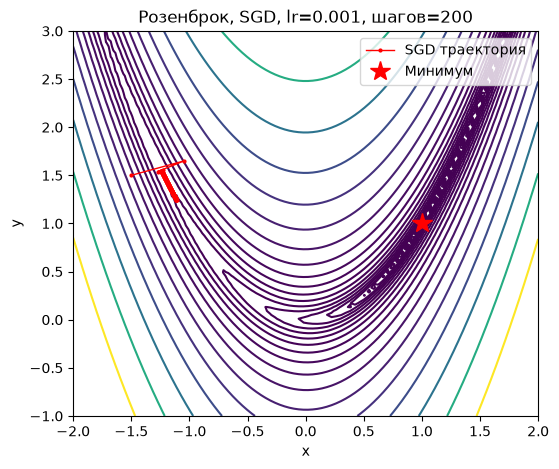

In [9]:
x0, y0 = -1.5, 1.5
lr = 0.001
steps = 200

x_hist, y_hist, f_hist = sgd_trajectory(rosenbrock, x0, y0, lr, steps)

# Визуализация
plt.figure(figsize=(6,5))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis')
plt.plot(x_hist, y_hist, 'r.-', markersize=4, linewidth=1, label='SGD траектория')
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Розенброк, SGD, lr={lr}, шагов={steps}')
plt.legend()
plt.show()

**Задание 4.** Поэкспериментируйте с learning rate и начальной точкой. Попробуйте для обеих функций:
- Попробовать 5 различных значений learning rate (например, 0.01, 0.05). Что происходит?
- Попробовать 5 различных начальных точек, например (0, 2) или (-1, -1) или случаным образом выбранных, надётся ли действительный глобальный минимум?

Результирующие графики всех экспериментов сохраните в отчётном блокноте.



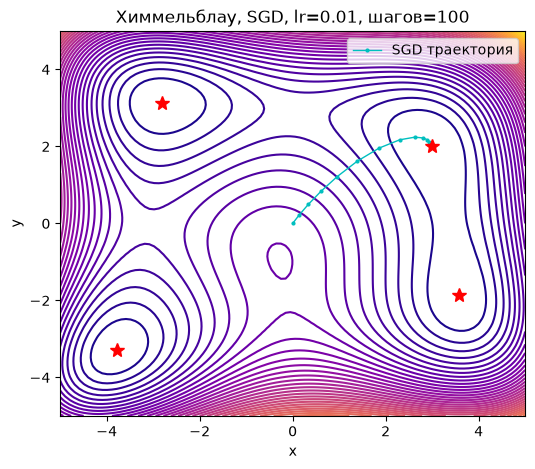

In [10]:
# Ваш эксперимент с Химмельблау
x0_h, y0_h = 0.0, 0.0
lr_h = 0.01
steps_h = 100

x_hist_h, y_hist_h, f_hist_h = sgd_trajectory(himmelblau, x0_h, y0_h, lr_h, steps_h)

plt.figure(figsize=(6,5))
plt.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma')
plt.plot(x_hist_h, y_hist_h, 'c.-', markersize=4, linewidth=1, label='SGD траектория')
# отметим минимумы
for mx, my in minima:
    plt.plot(mx, my, 'r*', markersize=10)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Химмельблау, SGD, lr={lr_h}, шагов={steps_h}')
plt.legend()
plt.show()

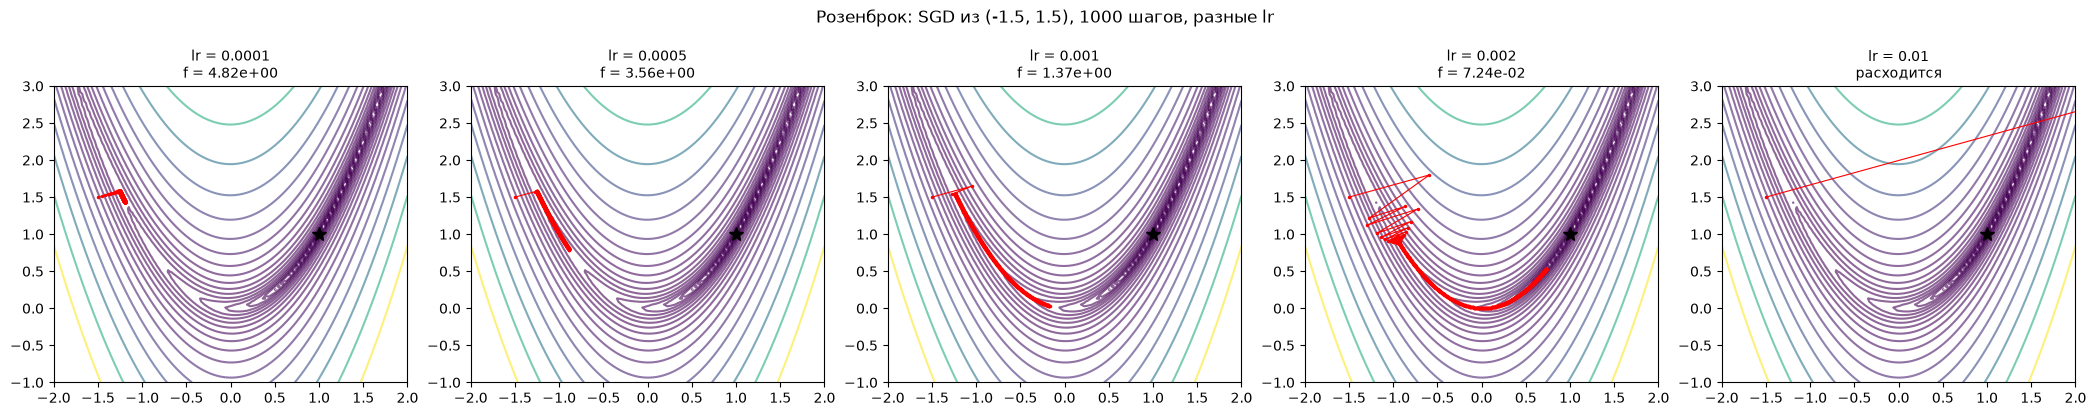

lr = 0.0001  конечная точка    (-1.193, 1.432)   f = 4.82e+00
lr = 0.0005  конечная точка    (-0.885, 0.792)   f = 3.56e+00
lr = 0.001   конечная точка    (-0.170, 0.033)   f = 1.37e+00
lr = 0.002   конечная точка     (0.731, 0.534)   f = 7.24e-02
lr = 0.01    конечная точка                  —   расходится


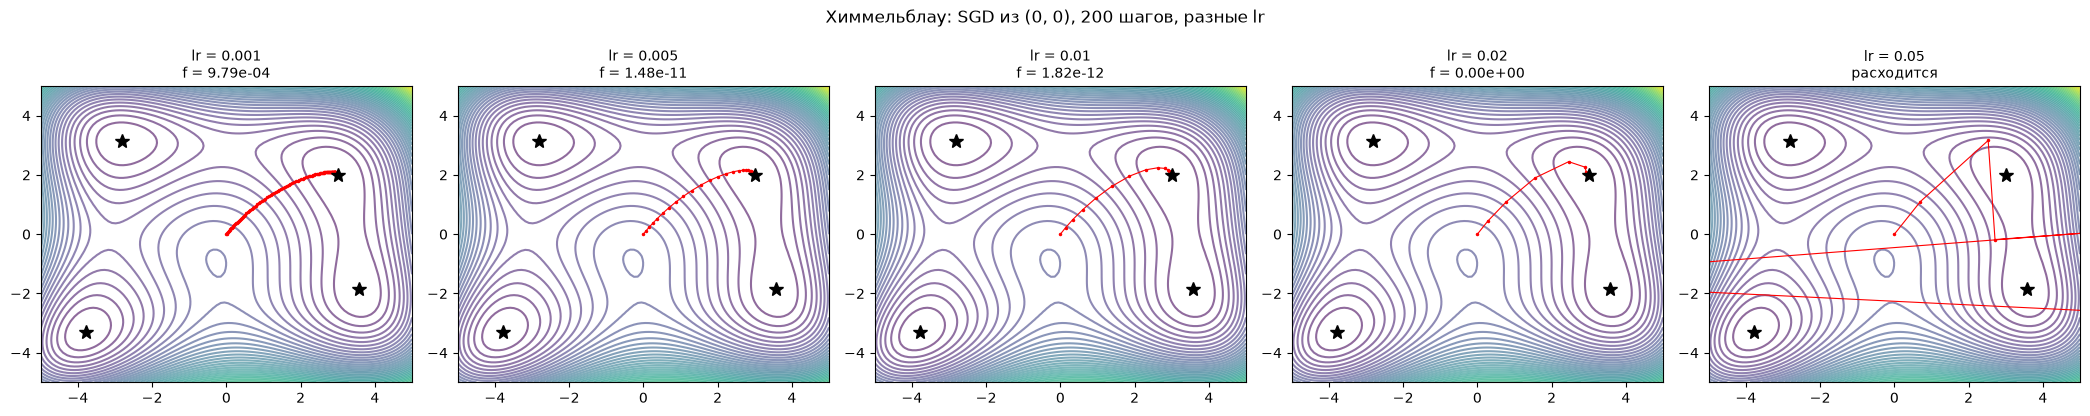

lr = 0.001   конечная точка     (2.997, 2.008)   f = 9.79e-04
lr = 0.005   конечная точка     (3.000, 2.000)   f = 1.48e-11
lr = 0.01    конечная точка     (3.000, 2.000)   f = 1.82e-12
lr = 0.02    конечная точка     (3.000, 2.000)   f = 0.00e+00
lr = 0.05    конечная точка                  —   расходится


In [11]:
# Задание 4а. Пять значений learning rate для каждой функции (одна и та же стартовая точка)
def safe(hist):
    """Обрезает расходящуюся траекторию (inf/nan), чтобы её можно было нарисовать."""
    a = np.array(hist, dtype=float)
    bad = ~np.isfinite(a) | (np.abs(a) > 1e6)
    return a[: np.argmax(bad)] if bad.any() else a

def run_grid(func, x0, y0, lrs, steps, Xg, Yg, Zg, levels, mins, title):
    fig, axes = plt.subplots(1, len(lrs), figsize=(4.2 * len(lrs), 4.2))
    rows = []
    for ax, lr in zip(axes, lrs):
        xh, yh, fh = sgd_trajectory(func, x0, y0, lr, steps)
        xs, ys = safe(xh), safe(yh)
        n = min(len(xs), len(ys))
        ax.contour(Xg, Yg, Zg, levels=levels, cmap="viridis", alpha=0.6)
        ax.plot(xs[:n], ys[:n], "r.-", ms=3, lw=0.8)
        for mx, my in mins:
            ax.plot(mx, my, "k*", ms=10)
        ax.set_xlim(Xg.min(), Xg.max()); ax.set_ylim(Yg.min(), Yg.max())
        diverged = n < steps or not np.isfinite(fh[-1])
        status = "расходится" if diverged else f"f = {fh[-1]:.2e}"
        ax.set_title(f"lr = {lr}\n{status}", fontsize=10)
        rows.append((lr, "—" if diverged else f"({xh[-1]:.3f}, {yh[-1]:.3f})", status))
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    for lr, pt, st in rows:
        print(f"lr = {lr:<7} конечная точка {pt:>18}   {st}")

run_grid(rosenbrock, -1.5, 1.5, [0.0001, 0.0005, 0.001, 0.002, 0.01], 1000, X, Y, Z_rosen,
         np.logspace(-1, 3, 20), [rosen_min], "Розенброк: SGD из (-1.5, 1.5), 1000 шагов, разные lr")
run_grid(himmelblau, 0.0, 0.0, [0.001, 0.005, 0.01, 0.02, 0.05], 200, X_h, Y_h, Z_himm,
         50, minima, "Химмельблау: SGD из (0, 0), 200 шагов, разные lr")

Розенброк, lr=0.001, 5000 шагов: старт (  0.0,   2.0) -> (0.957, 0.916), f = 1.85e-03, ближайший минимум (1.00, 1.00), расстояние 0.095


Розенброк, lr=0.001, 5000 шагов: старт ( -1.0,  -1.0) -> (0.956, 0.913), f = 1.98e-03, ближайший минимум (1.00, 1.00), расстояние 0.098


Розенброк, lr=0.001, 5000 шагов: старт (  0.5,  2.59) -> (1.086, 1.181), f = 7.49e-03, ближайший минимум (1.00, 1.00), расстояние 0.200


Розенброк, lr=0.001, 5000 шагов: старт (  1.1,  -0.1) -> (0.963, 0.928), f = 1.34e-03, ближайший минимум (1.00, 1.00), расстояние 0.081


Розенброк, lr=0.001, 5000 шагов: старт ( -0.8,  2.49) -> (0.917, 0.841), f = 6.83e-03, ближайший минимум (1.00, 1.00), расстояние 0.179


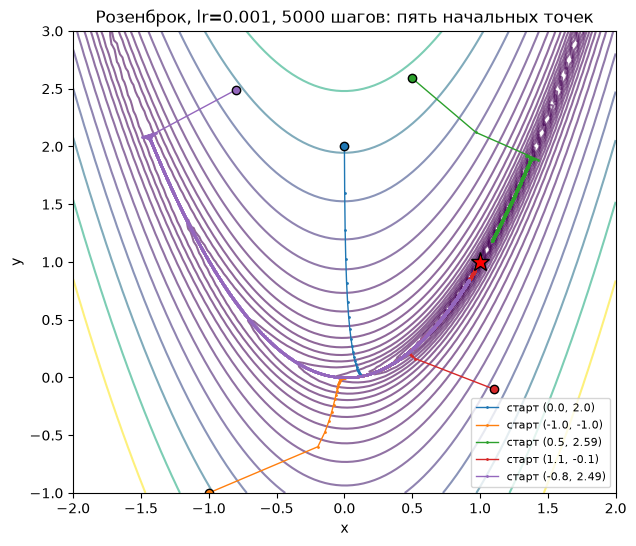

Химмельблау, lr=0.01, 200 шагов: старт (  0.0,   2.0) -> (3.000, 2.000), f = 1.82e-12, ближайший минимум (3.00, 2.00), расстояние 0.000
Химмельблау, lr=0.01, 200 шагов: старт ( -1.0,  -1.0) -> (-3.779, -3.283), f = 0.00e+00, ближайший минимум (-3.78, -3.28), расстояние 0.000
Химмельблау, lr=0.01, 200 шагов: старт (-4.95,  3.21) -> (-2.805, 3.131), f = 2.27e-13, ближайший минимум (-2.81, 3.13), расстояние 0.000
Химмельблау, lr=0.01, 200 шагов: старт ( 2.97, -0.32) -> (3.584, -1.848), f = 2.27e-13, ближайший минимум (3.58, -1.85), расстояние 0.000
Химмельблау, lr=0.01, 200 шагов: старт (-1.97, -2.22) -> (-3.779, -3.283), f = 0.00e+00, ближайший минимум (-3.78, -3.28), расстояние 0.000


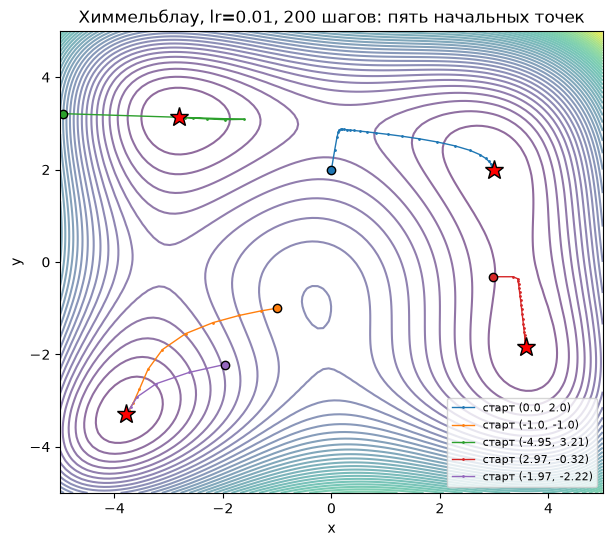

In [12]:
# Задание 4б. Пять начальных точек: (0, 2), (-1, -1) и три случайные
rng = np.random.default_rng(7)
def nearest_min(px, py, mins):
    d = [np.hypot(px - mx, py - my) for mx, my in mins]
    k = int(np.argmin(d))
    return k, d[k]

for func, lr, steps, box, Xg, Yg, Zg, levels, mins, name in [
        (rosenbrock, 0.001, 5000, (-2, 2, -1, 3), X, Y, Z_rosen, np.logspace(-1, 3, 20), [rosen_min], "Розенброк, lr=0.001, 5000 шагов"),
        (himmelblau, 0.01, 200, (-5, 5, -5, 5), X_h, Y_h, Z_himm, 50, minima, "Химмельблау, lr=0.01, 200 шагов")]:
    starts = [(0.0, 2.0), (-1.0, -1.0)] + [tuple(np.round(rng.uniform([box[0], box[2]], [box[1], box[3]]), 2)) for _ in range(3)]
    plt.figure(figsize=(7, 6))
    plt.contour(Xg, Yg, Zg, levels=levels, cmap="viridis", alpha=0.6)
    for k, (sx, sy) in enumerate(starts):
        xh, yh, fh = sgd_trajectory(func, sx, sy, lr, steps)
        xs, ys = safe(xh), safe(yh); n = min(len(xs), len(ys))
        plt.plot(xs[:n], ys[:n], ".-", ms=2, lw=1, color=f"C{k}", label=f"старт ({sx}, {sy})")
        plt.plot(sx, sy, "o", color=f"C{k}", mec="k")
        if n == steps and np.isfinite(fh[-1]):
            j, d = nearest_min(xh[-1], yh[-1], mins)
            print(f"{name}: старт ({sx:5}, {sy:5}) -> ({xh[-1]:.3f}, {yh[-1]:.3f}), f = {fh[-1]:.2e}, "
                  f"ближайший минимум ({mins[j][0]:.2f}, {mins[j][1]:.2f}), расстояние {d:.3f}")
        else:
            print(f"{name}: старт ({sx:5}, {sy:5}) -> расходится")
    for mx, my in mins:
        plt.plot(mx, my, "r*", ms=14, mec="k")
    plt.xlim(box[0], box[1]); plt.ylim(box[2], box[3])
    plt.title(f"{name}: пять начальных точек"); plt.legend(fontsize=8, loc="lower right")
    plt.xlabel("x"); plt.ylabel("y")
    plt.show()

**Скорость обучения, Розенброк** (старт (−1,5; 1,5), 1000 шагов):
- `0.0001` → f = 4,82, `0.0005` → f = 3,56, `0.001` → f = 1,37. Точка спускается на дно оврага и ползёт по нему, но до (1, 1) за 1000 шагов не доходит. Чем меньше lr, тем меньше пройденный путь.
- `0.002` → (0,731; 0,534), f = 0,072 — лучший результат. На рисунке первые шаги — зигзаг поперёк оврага: точка перескакивает со склона на склон. Потом колебания затухают, и точка идёт по дну.
- `0.01` → расходится: шаг поперёк оврага слишком велик, каждое следующее отклонение больше предыдущего.

Окно рабочих значений узкое: если увеличить lr в 5 раз (0,002 → 0,01), лучший вариант становится расходящимся.

**Скорость обучения, Химмельблау** (старт (0, 0), 200 шагов):
- `0.001` — точка ещё не дошла до минимума: (2,997; 2,008), f ≈ 1e−3;
- `0.005`, `0.01`, `0.02` — сходится к (3, 2), f от 1e−11 до 0;
- `0.05` — расходится.

Химмельблау устроена проще: подходят lr в 10 раз больше, чем у Розенброка, и диапазон рабочих значений шире.

**Начальные точки.**
- **Розенброк** (lr = 0,001, 5000 шагов). Из всех пяти стартов — (0, 2), (−1, −1) и трёх случайных — точка приходит в окрестность глобального минимума (1, 1), но не в сам минимум: расстояние 0,08–0,20, f от 1,3e−3 до 7,5e−3. Минимум у функции один, и найти его можно из любого старта, вопрос только в числе шагов.
- **Химмельблау** (lr = 0,01, 200 шагов). Каждый старт приходит точно в минимум (расстояние 0,000), но **в разные**:
  - (0, 2) → (3; 2);
  - (−1, −1) и (−1,97; −2,22) → (−3,78; −3,28);
  - (−4,95; 3,21) → (−2,81; 3,13);
  - (2,97; −0,32) → (3,58; −1,85).

  Градиентный спуск — локальный метод: он приходит в минимум той впадины, в которой начал. Все четыре минимума Химмельблау равны нулю, поэтому глобальным здесь оказывается любой из них. Если бы минимумы были разной глубины, результат зависел бы от удачного старта.

## 4. Сравнение оптимизаторов из torch.optim

PyTorch предоставляет готовые реализации многих оптимизаторов: SGD (с momentum и nesterov), RMSprop, Adam и др. Мы можем использовать их, передав параметры модели. В нашем случае модель — это просто два тензора x и y.

Напишем функцию, которая принимает оптимизатор (например, `torch.optim.SGD`), его параметры и возвращает траекторию.

In [13]:
def optimizer_trajectory(func, x0, y0, optim_class, optim_kwargs, steps=100):
    """
    Метод для конкретного оптимизатора и конкретной оптимизируемой функции реализует градиентный спуск.
    optim_class: наименование класса оптимизатора строкой (SGD, Adam, RMSprop)
    optim_kwargs: словарь параметров, например {'lr':0.01, 'momentum':0.9}
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    # Создаём оптимизатор, передав список параметров
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        # собственно обновление значений подбираемых параметров
        optimizer.step()

        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

    return x_hist, y_hist, f_hist

### 4.1 Сравнение на функции Розенброка
Возьмём начальную точку (-1.5, 1.5), 100 шагов, и сравним:
- SGD (learning rate = 0.001)
- SGD с моментом (lr=0.001, momentum=0.9)
- RMSprop (lr=0.01)
- Adam (lr=0.01)

Построим все траектории на одном контурном графике.

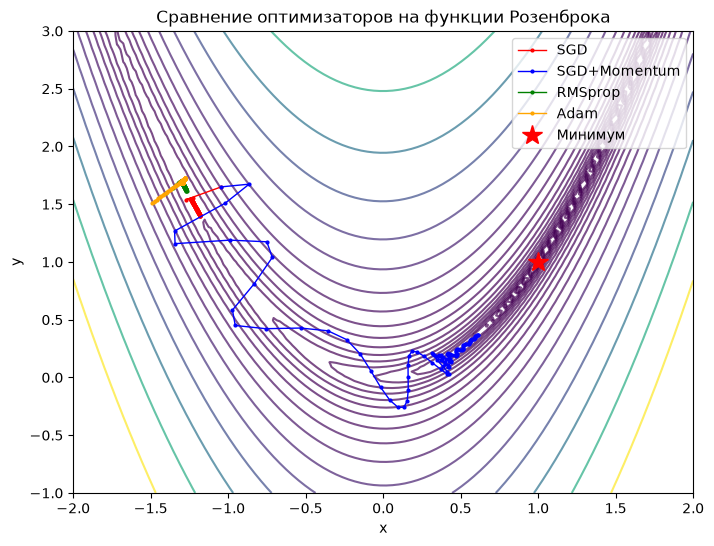

In [14]:
x0, y0 = -1.5, 1.5
steps = 100

# Словарь с оптимизаторами и их параметрами
optimizers = {
    'SGD': (torch.optim.SGD, {'lr': 0.001}),
    'SGD+Momentum': (torch.optim.SGD, {'lr': 0.001, 'momentum': 0.9}),
    'RMSprop': (torch.optim.RMSprop, {'lr': 0.01}),
    'Adam': (torch.optim.Adam, {'lr': 0.01})
}

trajectories = {}
for name, (opt_class, kwargs) in optimizers.items():
    xh, yh, fh = optimizer_trajectory(rosenbrock, x0, y0, opt_class, kwargs, steps)
    trajectories[name] = (xh, yh, fh)

# Построение
plt.figure(figsize=(8,6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.7)
colors = ['red', 'blue', 'green', 'orange']
for i, (name, (xh, yh, fh)) in enumerate(trajectories.items()):
    plt.plot(xh, yh, '.-', color=colors[i], linewidth=1, markersize=4, label=name)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Сравнение оптимизаторов на функции Розенброка')
plt.legend()
plt.show()

**Задание 5. Вопросы для анализа:**
- Какой оптимизатор быстрее достиг окрестности минимума?
- Как ведёт себя SGD без момента? Почему он "застревает" в овраге?
- Почему Adam и RMSprop работают лучше?
- Сравнить оптимизаторы по итоговому найденному значению минимизируемой функции.
- Сравнить времена работы (эффективность/производительность) оптимизаторов. Если на одинаковом количестве итераций они оказались примерно одинаковые, попробовать увеличить количество итераций так, чтобы 1-2 метода успели попасть в небольшую окрестность глобального минимума и сравнить методы по количеству этих итераций.


In [15]:
# Задание 5: итоговое значение функции после 100 шагов и время работы
print(f"{'оптимизатор':<14} {'f после 100 шагов':>18} {'конечная точка':>20} {'расст. до (1,1)':>16} {'время 100 шагов, мс':>21}")
for name, (opt_class, kwargs) in optimizers.items():
    t0 = time.perf_counter()
    for _ in range(20):                              # усредняем время по 20 запускам
        xh, yh, fh = optimizer_trajectory(rosenbrock, x0, y0, opt_class, kwargs, steps)
    dt = (time.perf_counter() - t0) / 20 * 1000
    f_end = rosenbrock(xh[-1], yh[-1])
    print(f"{name:<14} {f_end:>18.4f} {f'({xh[-1]:.3f}, {yh[-1]:.3f})':>20} {np.hypot(xh[-1] - 1, yh[-1] - 1):>16.3f} {dt:>21.1f}")

оптимизатор     f после 100 шагов       конечная точка  расст. до (1,1)   время 100 шагов, мс
SGD                        4.7541      (-1.179, 1.398)            2.215                   4.4
SGD+Momentum               0.1520       (0.614, 0.372)            0.737                   4.8


RMSprop                    5.1502      (-1.269, 1.615)            2.351                   5.7
Adam                       5.2652      (-1.292, 1.680)            2.391                   6.4


In [16]:
def optimizer_trajectory_1(func, x0, y0, optim_class, optim_kwargs, steps=100):
    """
    Метод для конкретного оптимизатора и конкретной оптимизируемой функции реализует градиентный спуск.
    optim_class: наименование класса оптимизатора строкой (SGD, Adam, RMSprop)
    optim_kwargs: словарь параметров, например {'lr':0.01, 'momentum':0.9}
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)
    eps = 0.05
    # Создаём оптимизатор, передав список параметров
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        # собственно обновление значений подбираемых параметров
        optimizer.step()

        if abs(x.item()-1)<eps and abs(y.item()-1)<eps:
            print("Количество итераций: "+str(i+1))
            break

        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

    return x_hist, y_hist, f_hist

SGD: 

Количество итераций: 7386
    время 0.33 с
SGD+Momentum: Количество итераций: 623
    время 0.03 с
RMSprop: 

Количество итераций: 3080
    время 0.17 с
Adam: 

Количество итераций: 4436
    время 0.28 с


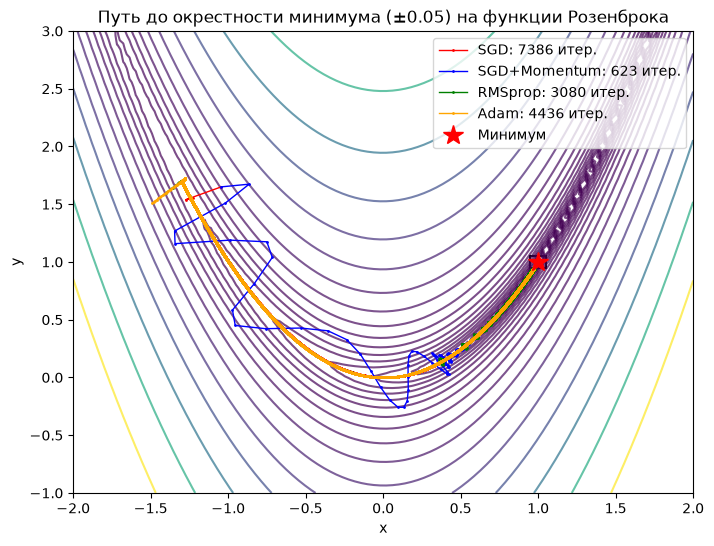

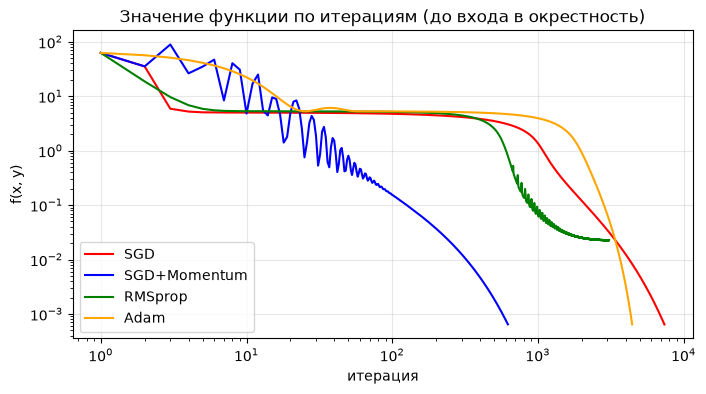

In [17]:
x0, y0 = -1.5, 1.5
steps = 20000

# Те же четыре оптимизатора, но шагов много: считаем, за сколько итераций каждый попадёт в квадрат
# |x - 1| < 0.05, |y - 1| < 0.05 вокруг минимума (функция optimizer_trajectory_1 останавливается сама)
trajectories_eps, iters_eps, time_eps = {}, {}, {}
for name, (opt_class, kwargs) in optimizers.items():
    print(f"{name}: ", end="")
    t0 = time.perf_counter()
    xh, yh, fh = optimizer_trajectory_1(rosenbrock, x0, y0, opt_class, kwargs, steps)
    time_eps[name] = time.perf_counter() - t0
    iters_eps[name] = len(xh) + 1 if len(xh) < steps else None
    if iters_eps[name] is None:
        print(f"за {steps} итераций окрестность не достигнута, конечная точка ({xh[-1]:.3f}, {yh[-1]:.3f})")
    trajectories_eps[name] = (xh, yh, fh)
    print(f"    время {time_eps[name]:.2f} с")

# Построение
plt.figure(figsize=(8,6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.7)
colors = ['red', 'blue', 'green', 'orange']
for i, (name, (xh, yh, fh)) in enumerate(trajectories_eps.items()):
    lbl = f"{name}: {iters_eps[name]} итер." if iters_eps[name] else f"{name}: > {steps} итер."
    plt.plot(xh, yh, '.-', color=colors[i], linewidth=1, markersize=2, label=lbl)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.gca().add_patch(plt.Rectangle((0.95, 0.95), 0.1, 0.1, fill=False, ec="k", lw=1.5))
plt.xlabel('x')
plt.ylabel('y')
plt.title('Путь до окрестности минимума (±0.05) на функции Розенброка')
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
for i, (name, (xh, yh, fh)) in enumerate(trajectories_eps.items()):
    plt.plot(np.arange(1, len(fh) + 1), np.maximum(fh, 1e-12), color=colors[i], label=name)
plt.xscale("log"); plt.yscale("log"); plt.grid(True, alpha=0.3)
plt.xlabel("итерация"); plt.ylabel("f(x, y)"); plt.legend()
plt.title("Значение функции по итерациям (до входа в окрестность)")
plt.show()

Траектории за 100 шагов — на рисунке выше, итоговые числа:

| оптимизатор | f после 100 шагов | расстояние до (1, 1) | итераций до квадрата ±0,05 | время до квадрата |
|---|---|---|---|---|
| SGD, lr = 0,001 | 4,754 | 2,215 | 7386 | 0,33 с |
| SGD + момент 0,9 | **0,152** | **0,737** | **623** | **0,03 с** |
| RMSprop, lr = 0,01 | 5,150 | 2,351 | 3080 | 0,17 с |
| Adam, lr = 0,01 | 5,265 | 2,391 | 4436 | 0,28 с |

1. **Быстрее всех до окрестности минимума дошёл SGD с моментом.** За 100 шагов он единственный спустился на дно оврага и прошёл большую часть пути (f = 0,15). До квадрата ±0,05 вокруг (1, 1) он дошёл за 623 итерации: в 12 раз быстрее обычного SGD и в 5–7 раз быстрее RMSprop и Adam. Момент накапливает скорость вдоль дна оврага, где градиент всё время направлен примерно в одну сторону. Поперёк оврага знак градиента чередуется, и там накопления нет.
2. **SGD без момента** за первые 2–3 шага спускается на дно оврага: на графике f по итерациям видно резкое падение примерно до 5. Потом примерно до 500-й итерации f почти не меняется. На дне градиент мал (длина 1–5, см. задание 3), шаг `lr · grad` составляет тысячные доли, и точка ползёт по дну. Отсюда 7386 итераций.
3. **Adam и RMSprop.** В этом эксперименте они лучше только обычного SGD (в 2,4 и 1,7 раза меньше итераций) и заметно хуже SGD с моментом. За 100 шагов они отстают даже от обычного SGD. Причина в их устройстве. Оба метода делят градиент на корень из скользящего среднего его квадрата, отдельно по каждой координате. Поэтому шаг по каждой координате получается порядка lr, независимо от величины градиента: поперёк оврага (градиент большой) они не раскачиваются, а вдоль дна (градиент маленький) не замедляются. В этом их преимущество на «овражных» функциях. Но при `lr = 0.01` шаг ≈ 0,01, а от старта до минимума ≈ 2,5, поэтому нужны сотни шагов. За 100 шагов Adam сместился лишь до (−1,29; 1,68). Значит, сравнение зависит от выбранных lr. При этих настройках (0,01 у адаптивных методов и 0,001 с моментом у SGD) выиграл момент.
4. **Итоговое значение функции** после 100 шагов: SGD + момент 0,152 ≪ SGD 4,754 < RMSprop 5,150 < Adam 5,265. У RMSprop на графике f по итерациям после ≈ 600-й итерации видны частые мелкие колебания: шаг порядка lr становится сравним с шириной дна оврага.
5. **Время.** На один шаг методы почти равны: 100 шагов занимают 4,4 мс у SGD, 4,8 мс у SGD + момент, 5,7 мс у RMSprop и 6,4 мс у Adam. Adam хранит и пересчитывает два скользящих средних, поэтому его шаг дороже. При одинаковом числе итераций время почти одинаковое, поэтому всё решает число итераций до квадрата ±0,05: SGD + момент 0,03 с, RMSprop 0,17 с, Adam 0,28 с, SGD 0,33 с.

### 4.2 Анимация траекторий (дополнительно)
Для наглядности можно создать анимацию движения точек. Ниже приведён код для создания GIF-анимации с помощью matplotlib.animation. Запустите эту ячейку, чтобы увидеть, как оптимизаторы "шагают" к минимуму.

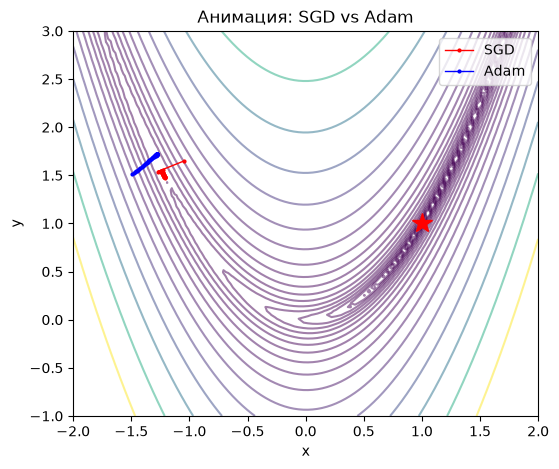

In [18]:
# Создаём анимацию для двух оптимизаторов: SGD и Adam
fig, ax = plt.subplots(figsize=(6,5))
ax.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
ax.plot(1, 1, 'r*', markersize=15)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Анимация: SGD vs Adam')

line_sgd, = ax.plot([], [], 'r.-', lw=1, markersize=4, label='SGD')
line_adam, = ax.plot([], [], 'b.-', lw=1, markersize=4, label='Adam')
ax.legend()

# Получаем траектории (первые steps точек) — из сравнения в разделе 4.1
steps_anim = 50  # возьмём первые 50 шагов для анимации
x_sgd, y_sgd = trajectories['SGD'][0][:steps_anim], trajectories['SGD'][1][:steps_anim]
x_adam, y_adam = trajectories['Adam'][0][:steps_anim], trajectories['Adam'][1][:steps_anim]

def init():
    line_sgd.set_data([], [])
    line_adam.set_data([], [])
    return line_sgd, line_adam

def animate(i):
    line_sgd.set_data(x_sgd[:i+1], y_sgd[:i+1])
    line_adam.set_data(x_adam[:i+1], y_adam[:i+1])
    return line_sgd, line_adam

anim = animation.FuncAnimation(fig, animate, init_func=init, frames=steps_anim, interval=100, blit=True)

# Для отображения в блокноте: видео (нужен ffmpeg), иначе — JS-анимация
try:
    video = HTML(anim.to_html5_video())
except Exception:
    video = HTML(anim.to_jshtml())
display(video)
# Ниже — последний кадр анимации как обычная картинка

## 5. Влияние скорости обучения (learning rate) на сходимость

Проведём эксперимент: зафиксируем начальную точку (-1.5, 1.5) и оптимизатор SGD (без момента). Будем менять learning rate: очень маленький (0.0001), средний (0.001), большой (0.01) и слишком большой (0.1). Наблюдаем поведение.

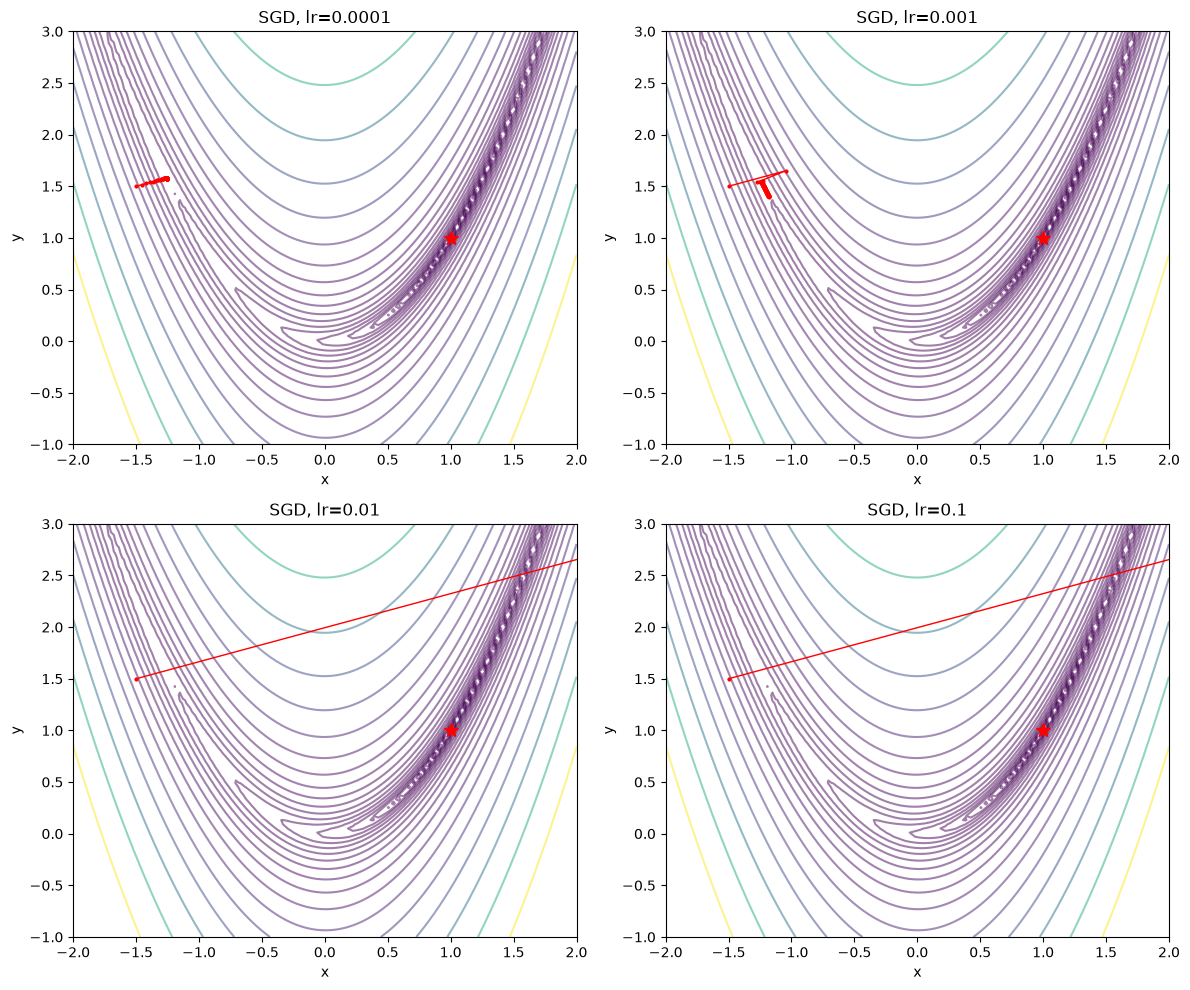

In [19]:
lrs_to_try = [0.0001, 0.001, 0.01, 0.1]
x0, y0 = -1.5, 1.5
steps = 100

plt.figure(figsize=(12,10))

for i, lr in enumerate(lrs_to_try):
    xh, yh, fh = sgd_trajectory(rosenbrock, x0, y0, lr, steps)
    plt.subplot(2,2,i+1)
    plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
    plt.plot(xh, yh, 'r.-', markersize=4, linewidth=1)
    plt.plot(1, 1, 'r*', markersize=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'SGD, lr={lr}')
    plt.xlim(-2,2)
    plt.ylim(-1,3)

plt.tight_layout()
plt.show()

**Обсуждение:**
- При очень маленьком LR (0.0001) алгоритм не успевает дойти до минимума за 100 шагов.
- При LR=0.001 траектория медленно сползает в овраг и движется к минимуму.
- При LR=0.01 шаги больше, но из-за оврага траектория может "перепрыгивать" и колебаться.
- При LR=0.1 градиентный спуск расходится: шаги становятся настолько большими, что точка улетает за пределы графика. Это иллюстрация "взрыва градиентов" (хотя здесь не градиенты взрываются, а слишком большой шаг).

**Задание 6.** Для функции Химмельблау и начальной точки (0, 0) подберите такое значение learning rate для SGD, чтобы алгоритм сошёлся к одному из минимумов, но при этом траектория была "интересной" (например, с колебаниями). Попробуйте также очень большое LR и посмотрите, куда улетает точка.

минимум (3.00, 2.00): λ_max = 82.3 -> колебания при lr > 0.0122, расходимость при lr > 0.0243
минимум (-2.81, 3.13): λ_max = 80.6 -> колебания при lr > 0.0124, расходимость при lr > 0.0248
минимум (-3.78, -3.28): λ_max = 133.8 -> колебания при lr > 0.0075, расходимость при lr > 0.0149
минимум (3.58, -1.85): λ_max = 105.4 -> колебания при lr > 0.0095, расходимость при lr > 0.0190


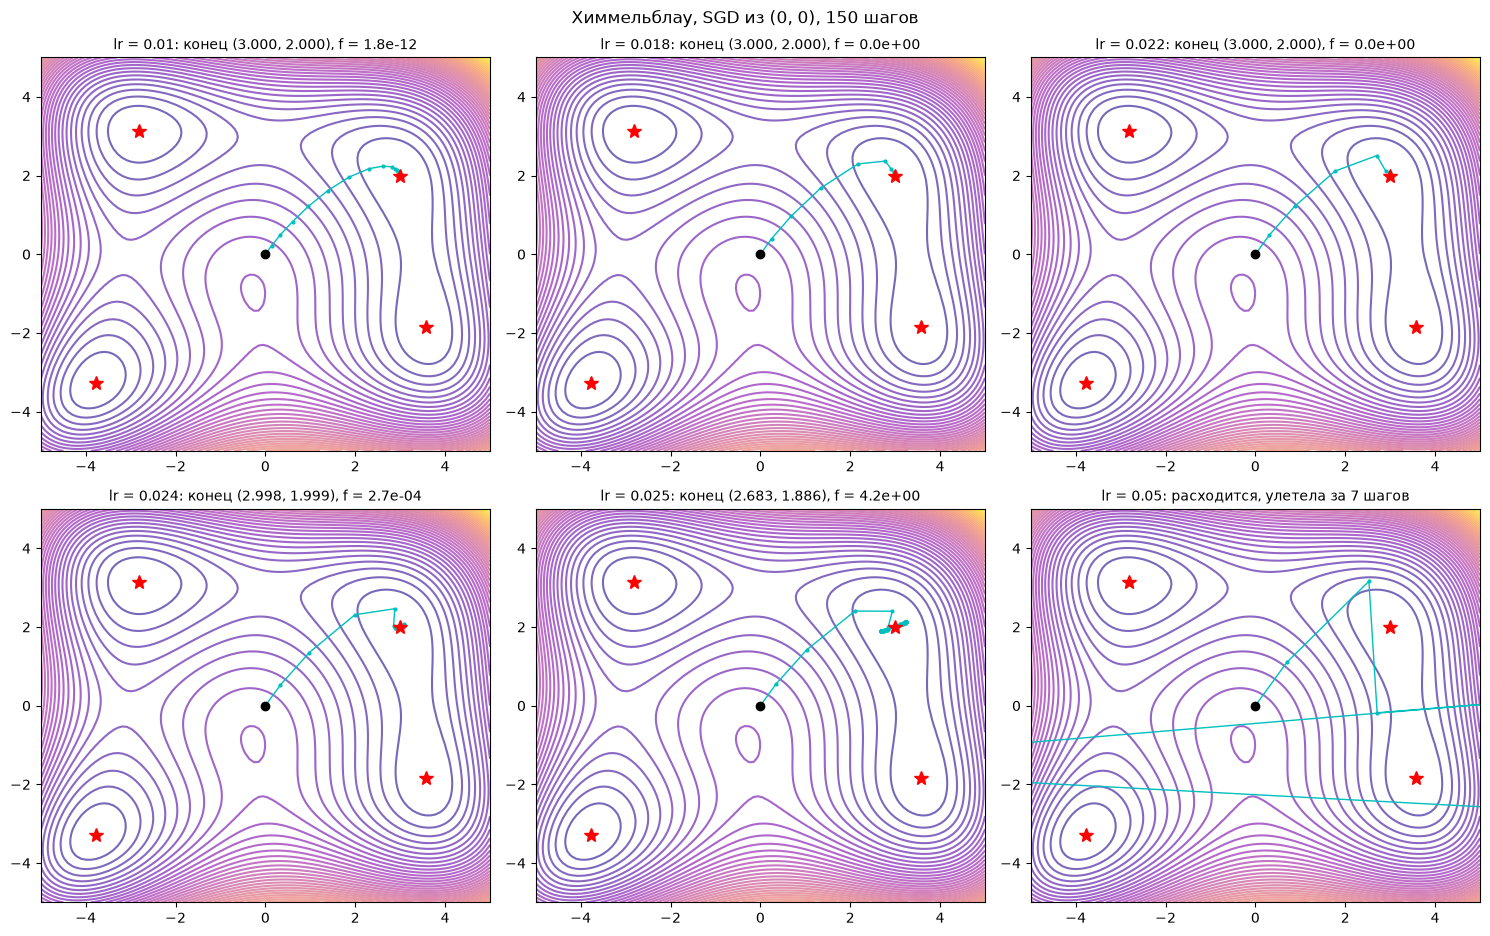

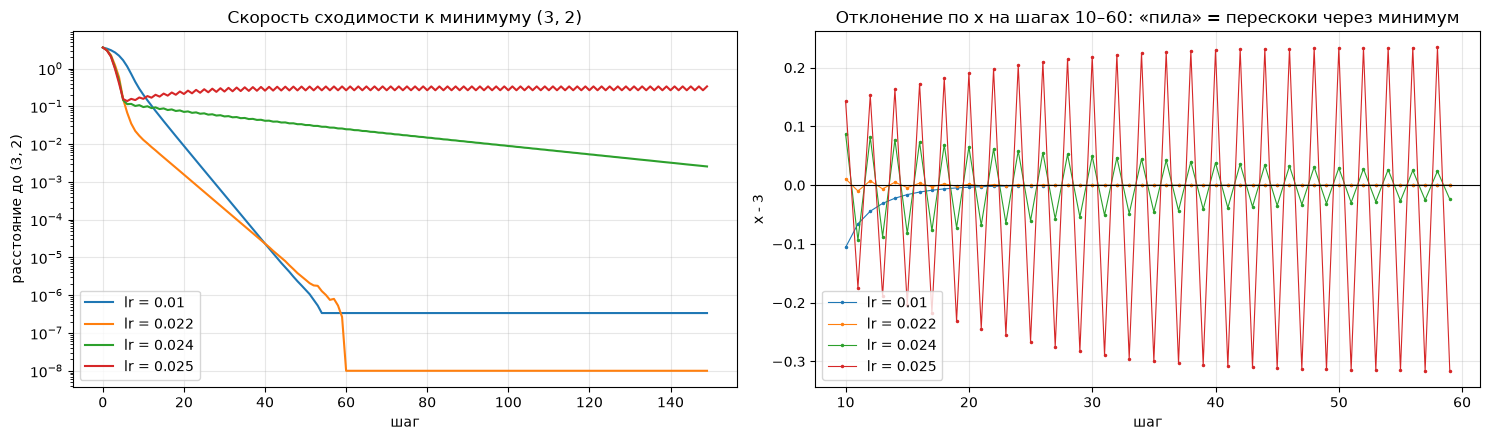

lr = 0.05: первые точки (0, 0), (0.7, 1.1), (2.53, 3.16), (2.71, -0.181), (5.21, 0.0479), (-11.5, -1.56)
lr = 0.1: первые точки (0, 0), (1.4, 2.2), (5.38, 4.24), (-45.7, -27.9), (3.73e+04, 7.65e+03), (-2.07e+13, -1.79e+11)
lr = 0.5: первые точки (0, 0), (7, 11), (-800, -2.7e+03), (1.01e+09, 3.94e+10), (-2.08e+27, -1.22e+32), (nan, nan)


In [20]:
# Эксперимент с Химмельблау и разными LR из точки (0, 0)
# Сначала оценим, где проходит граница устойчивости: для квадратичной функции SGD колеблется,
# если lr > 1/λ_max, и расходится, если lr > 2/λ_max (λ_max — наибольшее собственное число гессиана)
for m in minima:
    lam = hess_eig(himmelblau, m).max()
    print(f"минимум ({m[0]:.2f}, {m[1]:.2f}): λ_max = {lam:.1f} -> колебания при lr > {1/lam:.4f}, расходимость при lr > {2/lam:.4f}")

lrs_h = [0.01, 0.018, 0.022, 0.024, 0.025, 0.05]
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, lr in zip(axes.flat, lrs_h):
    xh, yh, fh = sgd_trajectory(himmelblau, 0.0, 0.0, lr, 150)
    xs, ys = safe(xh), safe(yh); n = min(len(xs), len(ys))
    ax.contour(X_h, Y_h, Z_himm, levels=50, cmap='plasma', alpha=0.6)
    ax.plot(xs[:n], ys[:n], 'c.-', ms=4, lw=1)
    ax.plot(0, 0, 'ko')
    for mx, my in minima:
        ax.plot(mx, my, 'r*', ms=10)
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    if n == 150 and np.isfinite(fh[-1]):
        ttl = f"lr = {lr}: конец ({xh[-1]:.3f}, {yh[-1]:.3f}), f = {fh[-1]:.1e}"
    else:
        ttl = f"lr = {lr}: расходится, улетела за {n} шагов"
    ax.set_title(ttl, fontsize=10)
plt.suptitle("Химмельблау, SGD из (0, 0), 150 шагов")
plt.tight_layout()
plt.show()

# Колебания можно увидеть по отклонению от минимума (3, 2): при перескоках знак x - 3 чередуется от шага к шагу
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for lr in [0.01, 0.022, 0.024, 0.025]:
    xh, yh, fh = sgd_trajectory(himmelblau, 0.0, 0.0, lr, 150)
    dist = np.hypot(np.array(xh) - 3, np.array(yh) - 2)
    axes[0].plot(np.maximum(dist, 1e-8), label=f"lr = {lr}")
    axes[1].plot(np.arange(10, 60), np.array(xh[10:60]) - 3, ".-", ms=3, lw=0.8, label=f"lr = {lr}")
axes[0].set_yscale("log"); axes[0].set_xlabel("шаг"); axes[0].set_ylabel("расстояние до (3, 2)")
axes[0].set_title("Скорость сходимости к минимуму (3, 2)"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("шаг"); axes[1].set_ylabel("x - 3")
axes[1].set_title("Отклонение по x на шагах 10–60: «пила» = перескоки через минимум")
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Очень большой шаг: куда улетает точка
for lr in [0.05, 0.1, 0.5]:
    xh, yh, fh = sgd_trajectory(himmelblau, 0.0, 0.0, lr, 10)
    print(f"lr = {lr}: первые точки " + ", ".join(f"({a:.3g}, {b:.3g})" for a, b in list(zip(xh, yh))[:6]))

Сначала посчитаны границы устойчивости. Вблизи минимума функция ведёт себя как квадратичная. Для квадратичной функции SGD колеблется (перескакивает минимум), если lr > 1/λ_max, и расходится, если lr > 2/λ_max. Траектория из (0, 0) приходит в минимум (3, 2). Для него λ_max = 82,3, поэтому границы равны 0,0122 и 0,0243.

Что видно на шести траекториях (150 шагов):
- `0.01` — ниже первой границы: плавный подход к (3, 2) без колебаний, f = 1,8e−12.
- `0.018` и `0.022` — между границами: точка подходит к минимуму с перескоками, но колебания быстро затухают, f = 0. У 0,022 на правом графике видно, что знак x − 3 чередуется от шага к шагу.
- **`0.024` — самая «интересная» траектория.** lr чуть меньше границы расходимости 0,0243, поэтому колебания затухают очень медленно: «пила» на правом графике за 50 шагов почти не уменьшается. Точка всё же сходится: через 150 шагов (2,998; 1,999), f = 2,7e−4.
- `0.025` — чуть выше границы: точка не улетает, но и не сходится. Она застревает в колебаниях вокруг (3, 2) с размахом около ±0,3 по x, f = 4,2. Здесь квадратичное приближение уже не работает: вдали от минимума кривизна меньше, и колебания не растут бесконечно.
- `0.05` — расходится: через 7 шагов точка уже за пределами графика.

**Очень большой lr.** Точка улетает почти сразу. При `0.05`: (0, 0) → (0,7; 1,1) → (2,53; 3,16) → (2,71; −0,18) → (5,21; 0,05) → (−11,5; −1,56). При `0.1` координаты за 5 шагов дошли до 1e13, при `0.5` — до 1e32, а дальше стали `nan`. Градиент функции Химмельблау растёт как куб координат. Поэтому каждый слишком длинный шаг уводит точку туда, где градиент ещё больше, и рост идёт лавинообразно.

## **6. Итоги занятия**

* Что нового узнали? (навыки/умения/знания).
* Что добавить/убрать/расписать подробнее/усложнить/упростить и т.д.


**Что нового.**
- Научился строить интерактивные 3D-поверхности в plotly.
- Научился сравнивать функции не только на глаз, но и по числам. Собственные числа гессиана (через `torch.autograd.functional.hessian`) сразу объясняют, почему функция Розенброка трудна для спуска и какие lr допустимы. Граница устойчивости 2/λ_max проверена на практике и сработала.
- Увидел, что сравнение оптимизаторов сильно зависит от выбранных lr: Adam не обязательно быстрее SGD с моментом.

**Что можно улучшить в практике.**
- В заготовке были ошибки. В задании 4 использовался нигде не заданный список `minima`. Ячейка с анимацией падала с `KeyError`, потому что предыдущая ячейка перезаписывала словарь `trajectories`. Подробнее — в начале тетрадки.
- Вопрос «Почему Adam и RMSprop работают лучше?» заранее предполагает результат, который при заданных lr не получается: за 100 шагов они хуже даже обычного SGD. Можно сформулировать вопрос нейтрально («сравните…») или дать такие lr, при которых адаптивные методы выигрывают.
- В задании 5 стоит сразу задать критерий «окрестности минимума» (здесь выбран квадрат ±0,05). Иначе число итераций у разных студентов несопоставимо.